# Thực hành 3 — Huấn luyện bộ lọc thư rác
Theo mục 4.2: `alpha=1.0`, `test_size=0.25`, `random_state=17`, `stratify=y`. Giữ nguyên cả ba câu thử không dấu trong mã mẫu.

Chọn **Run All** để chạy độc lập notebook này. Trên Colab, tải CSV cần dùng vào Files hoặc thư mục `data/`.


In [1]:
from pathlib import Path

# Chạy từ thư mục bài, code/, hoặc thư mục chứa CSV đã tải lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "tin_nhan.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Hãy giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)


## Mã và kết quả

In [2]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

df = pd.read_csv(tep_du_lieu("tin_nhan.csv"))
# Giữ thứ tự vector hóa rồi chia như mã d3 của tài liệu để đối chiếu.
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df["noi_dung"])
y = df["la_rac"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

print("So tin de hoc     :", X_train.shape[0])
print("So tin de kiem tra:", X_test.shape[0])
print()
mo_hinh = MultinomialNB(alpha=1.0)
mo_hinh.fit(X_train, y_train)
y_pred = mo_hinh.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Ma tran nham lan")
print(f"  TN = {tn:2d}   thu thuong duoc giu dung")
print(f"  FP = {fp:2d}   thu thuong bi xoa nham")
print(f"  FN = {fn:2d}   thu rac lot luoi")
print(f"  TP = {tp:2d}   thu rac bi chan dung")
print()
print(f"Accuracy  = {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision = {precision_score(y_test, y_pred):.4f}")
print(f"Recall    = {recall_score(y_test, y_pred):.4f}")
print()

tin_moi = [
    "trung thuong khuyen mai nhanh tay click ngay",
    "hop nhom bao cao chieu mai phong 305",
    "ban gui giup em tai lieu bai tap nhe",
]
X_moi = vec.transform(tin_moi)
p_rac = mo_hinh.predict_proba(X_moi)[:, 1]
print("Thu tren ba tin nhan tu go:")
for tin, p in zip(tin_moi, p_rac):
    nhan = "RAC" if p >= 0.5 else "thuong"
    print(f"  [{nhan:6s}] p = {p:.4f}  <- {tin}")

So tin de hoc     : 225
So tin de kiem tra: 75

Ma tran nham lan
  TN = 45   thu thuong duoc giu dung
  FP =  0   thu thuong bi xoa nham
  FN =  4   thu rac lot luoi
  TP = 26   thu rac bi chan dung

Accuracy  = 0.9467
Precision = 1.0000
Recall    = 0.8667

Thu tren ba tin nhan tu go:
  [RAC   ] p = 0.9992  <- trung thuong khuyen mai nhanh tay click ngay
  [thuong] p = 0.0983  <- hop nhom bao cao chieu mai phong 305
  [thuong] p = 0.0719  <- ban gui giup em tai lieu bai tap nhe


## Hình minh họa bổ sung
Phần vẽ dưới đây bổ sung cho mã mẫu; hình được lưu vào `figures/` trước khi hiển thị.

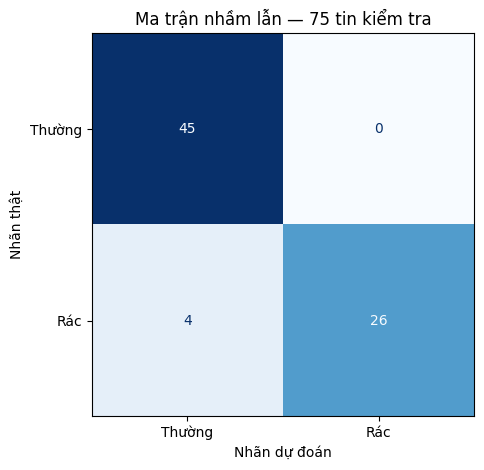

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Thường", "Rác"], cmap="Blues", colorbar=False
)
plt.title("Ma trận nhầm lẫn — 75 tin kiểm tra")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thật")
plt.tight_layout()
plt.savefig(thu_muc_hinh / "d3_ma_tran_nham_lan.png", dpi=150)
plt.show()